In [1]:
# ============================================================
# 강판 표면 결함 분류 - 검증 강화판 (v3)
# ============================================================
# gpt_claude 노트북을 바탕으로, 결과 해석에서 나온 4가지 점검을 반영한다.
#
# [점검 1] 그룹 기반 교차검증
#   데이터에 강판 ID가 없으므로 (Length_of_Conveyer, Steel_Plate_Thickness,
#   Steel_Type) 조합을 '유사 강판 그룹'으로 정의하고, 무작위 CV와 그룹 CV의
#   성능을 비교한다. 차이가 크면 모델이 결함 모양이 아니라
#   '어느 강판인지'를 외워서 맞히고 있다는 뜻이다.
#   + 강판 단위 변수(Length_of_Conveyer, Y 좌표)를 뺀 경우도 함께 비교한다.
#
# [점검 2] 클래스별 확률 배율의 중첩 검증
#   바깥 fold마다 안쪽 OOF 확률로 배율을 새로 찾고, 바깥 fold로 평가한다.
#   배율 탐색에 쓴 데이터로 평가하지 않으므로 보정의 실제 이득을 알 수 있다.
#   오탐 비용을 반영하기 위해, 지정한 클래스의 정밀도 하한을 지키는
#   '제약 보정'을 함께 비교한다.
#
# [점검 3] 대응(paired) 부트스트랩
#   claude4(v2), gpt_claude, 이번 최종 모델을 같은 개발 데이터로 다시 학습해
#   같은 테스트셋, 같은 부트스트랩 표본에서 점수 차이를 계산한다.
#
# [점검 4] Bumps ↔ Other_Faults 분석 및 라벨 오류 후보 추출
#   두 유형을 가르는 변수, 오분류가 몰리는 강판 그룹,
#   확신도가 높은데 틀린 행(라벨 오류 후보)을 정리해 CSV로 저장한다.
#
# 분할: 이전 노트북과 같은 개발 80% / 테스트 20% (같은 random_state, 층화)
#   → 테스트셋이 이전 두 노트북과 동일하므로 점수를 직접 비교할 수 있다.
#   모든 결정(배율 사용 여부 등)은 개발 데이터로만 내리고, 테스트는 마지막에 본다.
#
# 실행 시간: 일반 PC 기준 약 10~20분 (N_REPEATS, ABLATION_REPEATS로 조절)
# ============================================================

In [2]:
# ============================================================
# 0. 라이브러리 및 설정
# ============================================================

import time
import warnings

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    from IPython.display import display
except ImportError:
    display = print

from scipy.stats import chi2_contingency, binomtest
from sklearn.base import BaseEstimator, ClassifierMixin, clone
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    StratifiedGroupKFold,
)
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.inspection import permutation_importance
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import QuantileTransformer
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

plt.rcParams["font.family"] = "Malgun Gothic"   # macOS: "AppleGothic"
plt.rcParams["axes.unicode_minus"] = False

RANDOM_STATE = 42
DATA_PATH = "steel_plates_faults.csv"

# ---- 점검 1: 유사 강판 그룹 정의 ----
GROUP_COLS = ["Length_of_Conveyer", "Steel_Plate_Thickness", "Steel_Type"]
N_REPEATS = 2            # 무작위 CV / 그룹 CV 반복 횟수 (중첩 검증)
ABLATION_REPEATS = 1     # 변수 제거 실험 반복 횟수
PLATE_LEVEL_VARS = {
    "Length_of_Conveyer 제외": ["Length_of_Conveyer"],
    "Y 좌표 제외": ["Y_Minimum", "Y_Maximum"],
    "둘 다 제외": ["Length_of_Conveyer", "Y_Minimum", "Y_Maximum"],
}

# ---- 점검 2: 확률 보정 ----
# 오탐 비용이 큰 클래스에 정밀도 하한을 지정한다. 비워 두면({}) 제약 없이
# Macro F1만 최대화한다. 값은 현장의 오탐 비용에 맞게 정해야 한다.
PRECISION_FLOOR = {"Pastry": 0.70}
SCALE_GRID = np.round(np.arange(0.3, 3.01, 0.1), 2)
GAIN_CONSISTENCY = 0.6   # 보정 채택 조건: fold의 60% 이상에서 이득이 양수

# ---- 점검 3: 부트스트랩 ----
N_BOOT = 2000

# ---- 점검 4: 라벨 오류 후보 기준 ----
SUSPECT_P_LABEL = 0.15   # 원래 라벨의 OOF 확률이 이 값 미만이고
SUSPECT_P_OTHER = 0.70   # 다른 한 유형의 확률이 이 값 이상이면 후보
KNN_K = 10

STEEL_COLS = ["TypeOfSteel_A300", "TypeOfSteel_A400"]
FAULT_COLS = ["Pastry", "Z_Scratch", "K_Scatch", "Stains",
              "Dirtiness", "Bumps", "Other_Faults"]
TARGET = "Fault_Type"

N_CLASS = len(FAULT_COLS)
LABELS = list(range(N_CLASS))
class_to_int = {name: i for i, name in enumerate(FAULT_COLS)}
int_to_class = {i: name for name, i in class_to_int.items()}
STEEL_CODE = {"A300": 0, "A400": 1}
PASTRY = class_to_int["Pastry"]


def macro_f1(y_true, y_pred):
    return f1_score(y_true, y_pred, labels=LABELS, average="macro", zero_division=0)


def score_row(y_true, y_pred):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Balanced Acc": balanced_accuracy_score(y_true, y_pred),
        "Macro Precision": precision_score(y_true, y_pred, labels=LABELS,
                                           average="macro", zero_division=0),
        "Macro Recall": recall_score(y_true, y_pred, labels=LABELS,
                                     average="macro", zero_division=0),
        "Macro F1": macro_f1(y_true, y_pred),
    }


def class_prf(y_true, y_pred, k):
    """클래스 k의 정밀도, 재현율"""
    p = precision_score(y_true, y_pred, labels=[k], average=None, zero_division=0)[0]
    r = recall_score(y_true, y_pred, labels=[k], average=None, zero_division=0)[0]
    return p, r

In [3]:
# ============================================================
# 1. 데이터 불러오기 및 열 병합
# ============================================================

raw_df = pd.read_csv(DATA_PATH)
print("원본 데이터 크기:", raw_df.shape)
print("결측치:", raw_df.isna().sum().sum(), "/ 중복 행:", raw_df.duplicated().sum())

for cols, label in [(STEEL_COLS, "강종"), (FAULT_COLS, "결함 유형")]:
    missing = [c for c in cols if c not in raw_df.columns]
    if missing:
        raise ValueError(f"{label} 열이 없습니다: {missing}")
    if not raw_df[cols].isin([0, 1]).all().all():
        raise ValueError(f"{label} 열은 0 또는 1이어야 합니다.")
    if not (raw_df[cols].sum(axis=1) == 1).all():
        raise ValueError(f"{label}이(가) 정확히 하나로 정해지지 않는 행이 있습니다.")


def merge_columns(data: pd.DataFrame) -> pd.DataFrame:
    """강종 2열 → Steel_Type, 결함 7열 → Fault_Type (결함 열이 없으면 강종만)"""
    out = data.copy()
    if set(STEEL_COLS).issubset(out.columns):
        pos = out.columns.get_loc("TypeOfSteel_A300")
        steel = np.where(out["TypeOfSteel_A300"] == 1, "A300", "A400")
        out = out.drop(columns=STEEL_COLS)
        out.insert(pos, "Steel_Type", steel)
    if set(FAULT_COLS).issubset(out.columns):
        out[TARGET] = out[FAULT_COLS].idxmax(axis=1)
        out = out.drop(columns=FAULT_COLS)
    return out


df = merge_columns(raw_df).reset_index(drop=True)
print("병합 후 데이터 크기:", df.shape)

ct = pd.crosstab(df[TARGET], df["Steel_Type"]).reindex(FAULT_COLS)
chi2, p_value, dof, _ = chi2_contingency(ct)
cramers_v = np.sqrt(chi2 / (len(df) * (min(ct.shape) - 1)))
print(f"강종-결함 유형: Chi2 = {chi2:.1f}, p = "
      f"{'<0.001' if p_value < 0.001 else round(p_value, 4)}, Cramér's V = {cramers_v:.3f}")

원본 데이터 크기: (1941, 34)
결측치: 0 / 중복 행: 0
병합 후 데이터 크기: (1941, 27)
강종-결함 유형: Chi2 = 667.0, p = <0.001, Cramér's V = 0.586


In [4]:
# ============================================================
# 2. 입력 변수
# ============================================================
# gpt_claude 노트북의 교차검증에서 파생변수 3개는 이득이 없었으므로(0.7967 vs 0.7961)
# 원본 변수만 사용한다. build_features_v2는 claude4(v2) 모델 재현용이다(점검 3).
# ============================================================

def build_features(data: pd.DataFrame) -> pd.DataFrame:
    out = data.drop(columns=[TARGET], errors="ignore").copy()
    out["Steel_Type"] = out["Steel_Type"].map(STEEL_CODE)
    if out["Steel_Type"].isna().any():
        raise ValueError("Steel_Type에 A300 / A400 이외의 값이 있습니다.")
    return out


def build_features_v2(data: pd.DataFrame) -> pd.DataFrame:
    """claude4(v2) 노트북의 38개 변수 (비교용)"""
    out = build_features(data)
    out["X_Range"] = out["X_Maximum"] - out["X_Minimum"]
    out["Y_Range"] = out["Y_Maximum"] - out["Y_Minimum"]
    out["Aspect_Ratio"] = (out["X_Range"] + 1) / (out["Y_Range"] + 1)
    out["Luminosity_Range"] = out["Maximum_of_Luminosity"] - out["Minimum_of_Luminosity"]
    out["Mean_Luminosity"] = out["Sum_of_Luminosity"] / out["Pixels_Areas"]
    out["Perimeter_Area_Ratio"] = (out["X_Perimeter"] + out["Y_Perimeter"]) / out["Pixels_Areas"]
    conveyer = out["Length_of_Conveyer"]
    out["X_Min_Rel"] = out["X_Minimum"] / conveyer
    out["X_Max_Rel"] = out["X_Maximum"] / conveyer
    out["Edge_Dist"] = np.minimum(out["X_Minimum"], conveyer - out["X_Maximum"]).clip(lower=0)
    out["Edge_Dist_Rel"] = out["Edge_Dist"] / conveyer
    out["Lum_Contrast"] = out["Luminosity_Range"] / (out["Mean_Luminosity"] + 1)
    out["Thick_x_Steel"] = out["Steel_Plate_Thickness"] * (1 + out["Steel_Type"])
    return out


X_all = build_features(df)
feature_cols = X_all.columns.tolist()
y_all = df[TARGET].map(class_to_int).to_numpy()
print("입력 변수 수:", len(feature_cols))

입력 변수 수: 26


In [5]:
# ============================================================
# 3. [점검 1] 유사 강판 그룹 만들기
# ============================================================
# 같은 강판에서 나온 결함은 컨베이어 길이·두께·강종이 같다.
# 이 조합이 같은 행을 한 그룹으로 묶는다.
# 주의: 서로 다른 강판이라도 사양이 같으면 같은 그룹이 되므로,
#       이 그룹 CV는 '같은 사양의 강판이 학습에 없을 때'의 성능이다.
#       실제 강판 단위 CV보다 다소 보수적(비관적)인 추정일 수 있다.
# ============================================================

group_key = df[GROUP_COLS].astype(str).agg("|".join, axis=1)
group_id = pd.factorize(group_key)[0]
group_sizes = pd.Series(group_id).value_counts()

print(f"\n유사 강판 그룹 수: {len(group_sizes)}")
print(f"그룹 크기: 중앙값 {group_sizes.median():.0f}, 최대 {group_sizes.max()} "
      f"(전체의 {group_sizes.max() / len(df):.1%})")
print(f"행이 1개뿐인 그룹: {(group_sizes == 1).sum()}개")
if group_sizes.max() / len(df) > 0.2:
    print("⚠ 한 그룹이 전체의 20%를 넘습니다. 그룹 CV의 fold 크기가 고르지 않을 수 있습니다.")

# 그룹 순도: 그룹 안에서 가장 많은 결함 유형의 비율
purity = (pd.DataFrame({"g": group_id, "y": y_all})
          .groupby("g")["y"].agg(lambda s: s.value_counts(normalize=True).iloc[0]))
weighted_purity = (purity * group_sizes.reindex(purity.index)).sum() / len(df)
single_class_rows = group_sizes[purity[purity == 1].index].sum()
print(f"그룹 다수 유형 비율(행 가중): {weighted_purity:.1%}")
print(f"결함 유형이 하나뿐인 그룹에 속한 행: {single_class_rows}개 ({single_class_rows / len(df):.1%})")

# 기준선: '같은 그룹에서 가장 많았던 유형'으로만 예측하는 분류기 (무작위 CV)
# 결함 모양을 전혀 보지 않으므로, 이 점수가 높을수록 강판 정보만으로
# 맞힐 수 있는 여지(외워서 맞힐 위험)가 크다는 뜻이다.
def group_majority_oof(y, groups, cv):
    pred = np.empty_like(y)
    for tr, te in cv.split(np.zeros(len(y)), y, groups):
        tab = pd.DataFrame({"g": groups[tr], "y": y[tr]})
        mode = tab.groupby("g")["y"].agg(lambda s: s.value_counts().index[0])
        fallback = pd.Series(y[tr]).value_counts().index[0]
        pred[te] = pd.Series(groups[te]).map(mode).fillna(fallback).astype(int).to_numpy()
    return pred


gm_random = group_majority_oof(
    y_all, group_id, StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE))
print(f"\n[기준선] 그룹 다수결 분류기 (무작위 CV) Macro F1 = {macro_f1(y_all, gm_random):.4f}, "
      f"Accuracy = {accuracy_score(y_all, gm_random):.4f}")
print("  → 결함 모양을 보지 않고 강판 사양만으로 얻는 점수")


유사 강판 그룹 수: 239
그룹 크기: 중앙값 3, 최대 133 (전체의 6.9%)
행이 1개뿐인 그룹: 67개
그룹 다수 유형 비율(행 가중): 76.6%
결함 유형이 하나뿐인 그룹에 속한 행: 430개 (22.2%)

[기준선] 그룹 다수결 분류기 (무작위 CV) Macro F1 = 0.6948, Accuracy = 0.7069
  → 결함 모양을 보지 않고 강판 사양만으로 얻는 점수


In [6]:
# ============================================================
# 4. 개발 / 테스트 분할 (이전 노트북과 동일)
# ============================================================

idx_dev, idx_test = train_test_split(
    np.arange(len(df)), test_size=0.20, stratify=y_all, random_state=RANDOM_STATE
)
X_dev, X_test = X_all.iloc[idx_dev], X_all.iloc[idx_test]
y_dev, y_test = y_all[idx_dev], y_all[idx_test]
groups_dev = group_id[idx_dev]

print(f"개발: {len(idx_dev)}개 / 테스트: {len(idx_test)}개")
print("테스트 앞 5개 행 번호:", idx_test[:5].tolist(), "(이전 노트북: [904, 492, 232, 1093, 803])")

leak_share = np.isin(group_id[idx_test], groups_dev).mean()
print(f"테스트 행 중 같은 그룹이 개발 데이터에도 있는 비율: {leak_share:.1%}")

개발: 1552개 / 테스트: 389개
테스트 앞 5개 행 번호: [904, 492, 232, 1093, 803] (이전 노트북: [904, 492, 232, 1093, 803])
테스트 행 중 같은 그룹이 개발 데이터에도 있는 비율: 94.3%


In [7]:
# ============================================================
# 5. 모델 정의
# ============================================================
# 하이퍼파라미터는 gpt_claude 노트북의 튜닝 결과를 그대로 사용한다.
# (이번 노트북의 목적은 튜닝이 아니라 '평가 방법'의 점검이다.)
# ============================================================

LGBM_TUNED = dict(
    objective="multiclass", n_estimators=400, learning_rate=0.03,
    num_leaves=31, max_depth=5, min_child_samples=10,
    subsample=0.8, subsample_freq=1, colsample_bytree=1.0, reg_lambda=0,
    class_weight=None, random_state=RANDOM_STATE, n_jobs=1, verbose=-1,
)
ET_TUNED = dict(
    n_estimators=300, max_depth=20, min_samples_split=5, min_samples_leaf=1,
    max_features=0.5, class_weight="balanced",
    random_state=RANDOM_STATE, n_jobs=-1,
)
GPT_CLAUDE_SCALE = [2.2, 0.5, 1.0, 0.5, 1.9, 1.0, 1.0]

# claude4(v2) 최종 모델 설정 (트리 수는 v2의 조기 종료 결과)
V2_LGBM = dict(
    objective="multiclass", n_estimators=103, learning_rate=0.05,
    num_leaves=22, min_child_samples=30, subsample=0.7, subsample_freq=1,
    colsample_bytree=0.65, class_weight="balanced",
    random_state=RANDOM_STATE, n_jobs=1, verbose=-1,
)
V2_XGB = dict(
    n_estimators=186, learning_rate=0.05, max_depth=6,
    subsample=0.8, colsample_bytree=0.7, random_state=RANDOM_STATE, n_jobs=1,
)


def make_members():
    return [LGBMClassifier(**LGBM_TUNED), ExtraTreesClassifier(**ET_TUNED)]


class ScaledSoftVoting(BaseEstimator, ClassifierMixin):
    """여러 모델의 확률 평균 + 클래스별 배율 보정.
    학습 데이터에 없는 클래스가 있어도 7개 열로 맞춰서 반환한다."""

    def __init__(self, estimators, class_scale=None):
        self.estimators = estimators
        self.class_scale = class_scale

    def fit(self, X, y):
        self.estimators_ = [clone(e).fit(X, y) for e in self.estimators]
        self.classes_ = np.array(LABELS)
        return self

    def predict_proba(self, X):
        P = np.zeros((len(X), N_CLASS))
        for e in self.estimators_:
            P[:, e.classes_] += e.predict_proba(X)
        P /= len(self.estimators_)
        if self.class_scale is not None:
            P = P * np.asarray(self.class_scale)
            P = P / P.sum(axis=1, keepdims=True)
        return P

    def predict(self, X):
        return self.classes_[self.predict_proba(X).argmax(axis=1)]


def fit_predict_proba(members, X_tr, y_tr, X_te):
    return ScaledSoftVoting(members).fit(X_tr, y_tr).predict_proba(X_te)


def oof_proba(members, X, y, cv, groups=None):
    """교차검증 out-of-fold 확률 (행마다 그 행을 학습에 안 쓴 모델의 예측)"""
    P = np.zeros((len(y), N_CLASS))
    for tr, te in cv.split(X, y, groups):
        missing = set(LABELS) - set(np.unique(y[tr]))
        if missing:
            print(f"  ⚠ 학습 fold에 없는 유형: {[int_to_class[k] for k in missing]}")
        P[te] = fit_predict_proba(members, X.iloc[tr], y[tr], X.iloc[te])
    return P


def make_cv(scheme, seed):
    if scheme == "그룹 CV":
        return StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=seed)
    return StratifiedKFold(n_splits=5, shuffle=True, random_state=seed)


# ---- 클래스별 확률 배율 탐색 (정밀도 하한 제약 지원) ----

def scale_objective(P, y, w, floor):
    pred = (P * w).argmax(axis=1)
    s = macro_f1(y, pred)
    for cname, lo in (floor or {}).items():
        p, _ = class_prf(y, pred, class_to_int[cname])
        s -= 10.0 * max(0.0, lo - p)       # 하한 미달분에 큰 벌점
    return s


def tune_class_scale(P, y, floor=None, n_rounds=3):
    """확률에 클래스별 배율을 곱해 argmax 했을 때 목적함수가 최대가 되는 배율.
    배율 > 1: 그 클래스를 더 자주 예측(재현율↑ 정밀도↓), < 1: 반대."""
    w = np.ones(N_CLASS)
    best = scale_objective(P, y, w, floor)
    for _ in range(n_rounds):
        improved = False
        for k in range(N_CLASS):
            for g in SCALE_GRID:
                trial = w.copy()
                trial[k] = g
                s = scale_objective(P, y, trial, floor)
                if s > best + 1e-9:
                    best, w, improved = s, trial, True
        if not improved:
            break
    return w

In [8]:
# ============================================================
# 6. [점검 1 + 2] 중첩 교차검증: 무작위 CV vs 그룹 CV, 보정 없음 vs 보정
# ============================================================
# 바깥 fold: 성능 평가용
# 안쪽 fold: 바깥 학습 데이터 안에서 OOF 확률을 만들어 배율을 찾는 용도
# 안쪽 fold도 바깥과 같은 방식(그룹이면 그룹)으로 나눈다.
# 개발 데이터(1552개)만 사용하고 테스트는 건드리지 않는다.
# ============================================================

METHODS = ["보정 없음", "자유 보정", "제약 보정"] if PRECISION_FLOOR else ["보정 없음", "자유 보정"]


def nested_eval(X, y, groups, scheme, seed):
    rows, scales = [], []
    P_outer = np.zeros((len(y), N_CLASS))
    outer = make_cv(scheme, seed)
    for fold, (tr, te) in enumerate(outer.split(X, y, groups)):
        X_tr, y_tr, g_tr = X.iloc[tr], y[tr], groups[tr]
        X_te, y_te = X.iloc[te], y[te]

        P_in = oof_proba(make_members(), X_tr, y_tr, make_cv(scheme, seed + 100), g_tr)
        w = {"보정 없음": np.ones(N_CLASS), "자유 보정": tune_class_scale(P_in, y_tr)}
        if PRECISION_FLOOR:
            w["제약 보정"] = tune_class_scale(P_in, y_tr, PRECISION_FLOOR)

        P_te = fit_predict_proba(make_members(), X_tr, y_tr, X_te)
        P_outer[te] = P_te

        for m in METHODS:
            pred = (P_te * w[m]).argmax(axis=1)
            pp, pr = class_prf(y_te, pred, PASTRY)
            rows.append({"Scheme": scheme, "Repeat": seed, "Fold": fold, "Method": m,
                         "Macro F1": macro_f1(y_te, pred),
                         "Pastry Precision": pp, "Pastry Recall": pr})
            if m != "보정 없음":
                scales.append({"Scheme": scheme, "Repeat": seed, "Fold": fold, "Method": m,
                               **dict(zip(FAULT_COLS, w[m]))})
    return rows, scales, P_outer


start = time.time()
nested_rows, scale_rows, oof_by_scheme = [], [], {"무작위 CV": [], "그룹 CV": []}
for scheme in ["무작위 CV", "그룹 CV"]:
    for r in range(N_REPEATS):
        print(f"{scheme} 반복 {r + 1}/{N_REPEATS} ...")
        rows, scales, P = nested_eval(X_dev, y_dev, groups_dev, scheme, RANDOM_STATE + r)
        nested_rows += rows
        scale_rows += scales
        oof_by_scheme[scheme].append(P)
print(f"소요 시간: {time.time() - start:.0f}초")

nested_df = pd.DataFrame(nested_rows)
scale_df = pd.DataFrame(scale_rows)

무작위 CV 반복 1/2 ...
무작위 CV 반복 2/2 ...
그룹 CV 반복 1/2 ...
그룹 CV 반복 2/2 ...
소요 시간: 185초



[무작위 CV vs 그룹 CV - Macro F1 (보정 없음)]


,mean,std
Scheme,,
무작위 CV,0.8265,0.0167
그룹 CV,0.7041,0.0679


차이(무작위 - 그룹) = +0.1224
→ 차이가 큼: 새 사양의 강판에서는 성능이 눈에 띄게 떨어질 것으로 예상된다.

[결함 유형별 F1 (OOF, 보정 없음)]


,무작위 CV,그룹 CV,차이
Other_Faults,0.7599,0.6768,0.0831
Z_Scratch,0.9386,0.8680,0.0707
Pastry,0.6317,0.5614,0.0704
K_Scatch,0.9645,0.9097,0.0548
Dirtiness,0.8625,0.8101,0.0524
Bumps,0.6893,0.6484,0.0409
Stains,0.9474,0.9600,-0.0126


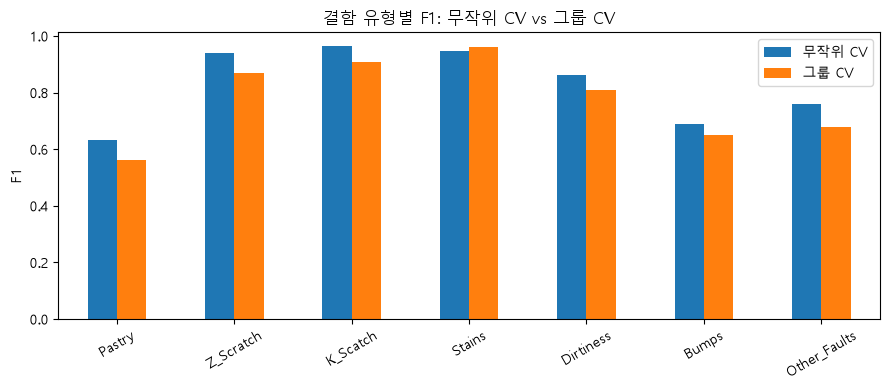

In [9]:
# ============================================================
# 6-1. [점검 1] 결과: 무작위 CV vs 그룹 CV (보정 없음 기준)
# ============================================================

raw = nested_df[nested_df["Method"] == "보정 없음"]
cv_compare = raw.groupby("Scheme")["Macro F1"].agg(["mean", "std"]).reindex(["무작위 CV", "그룹 CV"])
print("\n[무작위 CV vs 그룹 CV - Macro F1 (보정 없음)]")
display(cv_compare.round(4))

group_gap = cv_compare.loc["무작위 CV", "mean"] - cv_compare.loc["그룹 CV", "mean"]
print(f"차이(무작위 - 그룹) = {group_gap:+.4f}")
if group_gap < 0.02:
    print("→ 차이가 작음: 성능이 '강판 외우기'에 크게 의존하지 않는다.")
elif group_gap < 0.05:
    print("→ 차이가 중간: 일부 성능은 같은 사양 강판의 정보에서 나온다.")
else:
    print("→ 차이가 큼: 새 사양의 강판에서는 성능이 눈에 띄게 떨어질 것으로 예상된다.")

# 결함 유형별 F1: 어떤 유형이 그룹 분할에서 크게 떨어지는가
per_class = {}
for scheme, Ps in oof_by_scheme.items():
    f1s = [f1_score(y_dev, P.argmax(axis=1), labels=LABELS, average=None, zero_division=0)
           for P in Ps]
    per_class[scheme] = np.mean(f1s, axis=0)
per_class_df = pd.DataFrame(per_class, index=FAULT_COLS)
per_class_df["차이"] = per_class_df["무작위 CV"] - per_class_df["그룹 CV"]
print("\n[결함 유형별 F1 (OOF, 보정 없음)]")
display(per_class_df.sort_values("차이", ascending=False).round(4))

per_class_df[["무작위 CV", "그룹 CV"]].plot(kind="bar", figsize=(9, 4))
plt.title("결함 유형별 F1: 무작위 CV vs 그룹 CV")
plt.ylabel("F1")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [10]:
# ============================================================
# 6-2. [점검 1] 강판 단위 변수 제거 실험
# ============================================================
# 무작위 CV에서는 떨어지는데 그룹 CV에서는 안 떨어지면(또는 오르면),
# 그 변수는 결함 특성보다 '강판 식별' 용도로 쓰이고 있었다는 뜻이다.
# ============================================================

ablation_rows = []
feature_sets = {"전체 변수": []} | PLATE_LEVEL_VARS
for set_name, drop_cols in feature_sets.items():
    X_sub = X_dev.drop(columns=drop_cols)
    for scheme in ["무작위 CV", "그룹 CV"]:
        for r in range(ABLATION_REPEATS):
            P = oof_proba(make_members(), X_sub, y_dev,
                          make_cv(scheme, RANDOM_STATE + r), groups_dev)
            ablation_rows.append({"Feature Set": set_name, "Scheme": scheme,
                                  "Macro F1": macro_f1(y_dev, P.argmax(axis=1))})

ablation_df = (pd.DataFrame(ablation_rows)
               .groupby(["Feature Set", "Scheme"])["Macro F1"].mean()
               .unstack().reindex(list(feature_sets))[["무작위 CV", "그룹 CV"]])
ablation_df["무작위 CV 변화"] = ablation_df["무작위 CV"] - ablation_df.loc["전체 변수", "무작위 CV"]
ablation_df["그룹 CV 변화"] = ablation_df["그룹 CV"] - ablation_df.loc["전체 변수", "그룹 CV"]
print("\n[강판 단위 변수 제거 실험 - OOF Macro F1]")
display(ablation_df.round(4))


[강판 단위 변수 제거 실험 - OOF Macro F1]


Scheme,무작위 CV,그룹 CV,무작위 CV 변화,그룹 CV 변화
Feature Set,,,,
전체 변수,0.8236,0.7724,0.0000,0.0000
Length_of_Conveyer 제외,0.7915,0.7719,-0.0321,-0.0005
Y 좌표 제외,0.8092,0.7711,-0.0145,-0.0014
둘 다 제외,0.7853,0.7560,-0.0384,-0.0164


In [11]:
# ============================================================
# 6-3. [점검 2] 결과: 확률 보정의 중첩 검증
# ============================================================

summary = (nested_df.groupby(["Scheme", "Method"])
           [["Macro F1", "Pastry Precision", "Pastry Recall"]].mean()
           .reindex(pd.MultiIndex.from_product([["무작위 CV", "그룹 CV"], METHODS])))

pivot = nested_df.pivot_table(index=["Scheme", "Repeat", "Fold"],
                              columns="Method", values="Macro F1")
for m in METHODS[1:]:
    gain = pivot[m] - pivot["보정 없음"]
    for scheme in ["무작위 CV", "그룹 CV"]:
        g = gain.xs(scheme, level="Scheme")
        summary.loc[(scheme, m), "이득(평균)"] = g.mean()
        summary.loc[(scheme, m), "이득>0 fold 비율"] = (g > 0).mean()

print("\n[확률 보정 중첩 검증 - 바깥 fold 평균]")
display(summary.round(4))

print("\n[fold별로 찾은 배율 - 안정성 확인 (평균 ± 표준편차)]")
display(scale_df.groupby(["Scheme", "Method"])[FAULT_COLS].agg(["mean", "std"]).round(2).T)

# 배율 사용 여부 결정 (그룹 CV 기준: 새 강판에 대한 성능을 우선)
# 정밀도 하한이 지정되어 있으면 그것은 현장 요구사항이므로 '제약 보정'만 후보로 둔다.
candidate_method = "제약 보정" if PRECISION_FLOOR else "자유 보정"
g_gain = (pivot[candidate_method] - pivot["보정 없음"]).xs("그룹 CV", level="Scheme")
USE_SCALE = (g_gain.mean() > 0) and ((g_gain > 0).mean() >= GAIN_CONSISTENCY)
FINAL_METHOD = candidate_method if USE_SCALE else "보정 없음"
print(f"\n후보 방식: {candidate_method} | 그룹 CV 평균 이득 {g_gain.mean():+.4f}, "
      f"이득>0 fold 비율 {(g_gain > 0).mean():.0%}")
print("→ 최종 방식:", FINAL_METHOD)


[확률 보정 중첩 검증 - 바깥 fold 평균]


Macro F1  Pastry Precision  Pastry Recall  이득(평균)  이득>0 fold 비율
무작위 CV 보정 없음    0.8265            0.7064         0.5754     NaN           NaN
       자유 보정    0.8289            0.6237         0.6669  0.0024           0.5
       제약 보정    0.8191            0.7344         0.4995 -0.0074           0.4
그룹 CV  보정 없음    0.7041            0.5983         0.5368     NaN           NaN
       자유 보정    0.7028            0.5820         0.5843 -0.0012           0.4
       제약 보정    0.6845            0.6925         0.3388 -0.0195           0.1


[fold별로 찾은 배율 - 안정성 확인 (평균 ± 표준편차)]


Scheme            그룹 CV       무작위 CV      
Method            자유 보정 제약 보정  자유 보정 제약 보정
Pastry       mean  1.43  0.37   1.99  0.74
             std   0.65  0.13   0.55  0.25
Z_Scratch    mean  1.76  1.69   0.97  1.13
             std   0.48  0.88   0.36  0.19
K_Scatch     mean  1.11  1.26   1.32  1.25
             std   0.62  0.75   0.62  0.46
Stains       mean  0.86  0.85   0.52  0.53
             std   0.38  0.40   0.28  0.28
Dirtiness    mean  2.19  2.18   1.81  1.76
             std   0.72  0.48   0.51  0.43
Bumps        mean  1.13  1.68   1.30  1.24
             std   0.24  0.66   0.40  0.37
Other_Faults mean  0.98  0.99   0.97  0.92
             std   0.06  0.19   0.09  0.10


후보 방식: 제약 보정 | 그룹 CV 평균 이득 -0.0195, 이득>0 fold 비율 10%
→ 최종 방식: 보정 없음


,Pastry 배율,정밀도,재현율,Pastry F1,Macro F1,오탐 수,미탐 수,Pastry 예측 수
0,0.3,0.690,0.317,0.435,0.756,18,86,58
3,0.6,0.655,0.437,0.524,0.770,29,71,84
6,0.9,0.582,0.508,0.542,0.772,46,62,110
9,1.2,0.551,0.556,0.553,0.773,57,56,127
12,1.5,0.533,0.579,0.555,0.773,64,53,137
15,1.8,0.537,0.627,0.579,0.777,68,47,147
18,2.1,0.512,0.659,0.576,0.775,79,43,162
21,2.4,0.503,0.690,0.582,0.776,86,39,173
24,2.7,0.479,0.738,0.581,0.776,101,33,194
27,3.0,0.465,0.746,0.573,0.775,108,32,202


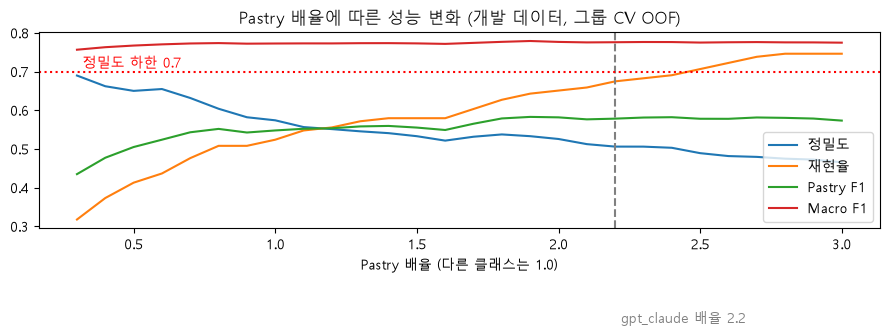

In [12]:
# ============================================================
# 6-4. [점검 2] Pastry 배율에 따른 정밀도 / 재현율 변화
# ============================================================
# 개발 데이터 전체의 그룹 CV OOF 확률에서 Pastry 배율만 바꿔 본다.
# 오탐 1건과 미탐 1건의 비용을 비교해 배율을 정하는 데 참고한다.
# ============================================================

P_dev_group = oof_proba(make_members(), X_dev, y_dev,
                        make_cv("그룹 CV", RANDOM_STATE), groups_dev)

sweep = []
for s in SCALE_GRID:
    w = np.ones(N_CLASS)
    w[PASTRY] = s
    pred = (P_dev_group * w).argmax(axis=1)
    p, r = class_prf(y_dev, pred, PASTRY)
    n_pred = (pred == PASTRY).sum()
    sweep.append({"Pastry 배율": s, "정밀도": p, "재현율": r,
                  "Pastry F1": f1_score(y_dev, pred, labels=[PASTRY], average=None, zero_division=0)[0],
                  "Macro F1": macro_f1(y_dev, pred),
                  "오탐 수": int(((pred == PASTRY) & (y_dev != PASTRY)).sum()),
                  "미탐 수": int(((pred != PASTRY) & (y_dev == PASTRY)).sum()),
                  "Pastry 예측 수": int(n_pred)})
sweep_df = pd.DataFrame(sweep)
display(sweep_df.iloc[::3].round(3))

fig, ax = plt.subplots(figsize=(9, 4))
for col in ["정밀도", "재현율", "Pastry F1", "Macro F1"]:
    ax.plot(sweep_df["Pastry 배율"], sweep_df[col], label=col)
ax.axvline(2.2, ls="--", c="gray")
ax.text(2.22, 0.05, "gpt_claude 배율 2.2", color="gray")
for cname, lo in PRECISION_FLOOR.items():
    if cname == "Pastry":
        ax.axhline(lo, ls=":", c="red")
        ax.text(0.32, lo + 0.01, f"정밀도 하한 {lo}", color="red")
ax.set_xlabel("Pastry 배율 (다른 클래스는 1.0)")
ax.set_title("Pastry 배율에 따른 성능 변화 (개발 데이터, 그룹 CV OOF)")
ax.legend()
plt.tight_layout()
plt.show()

In [13]:
# ============================================================
# 7. 최종 모델 학습 및 테스트 평가
# ============================================================
# 배율은 개발 데이터의 그룹 CV OOF 확률로 찾는다.
# (무작위 CV OOF는 같은 강판 정보 덕분에 확률이 과신되는 경향이 있어서)
# ============================================================

if FINAL_METHOD == "보정 없음":
    final_scale = None
else:
    floor = PRECISION_FLOOR if FINAL_METHOD == "제약 보정" else None
    final_scale = tune_class_scale(P_dev_group, y_dev, floor)
    print("최종 클래스 배율:")
    display(pd.Series(final_scale, index=FAULT_COLS, name="배율").round(2))

final_model = ScaledSoftVoting(make_members(), class_scale=final_scale).fit(X_dev, y_dev)
y_pred = final_model.predict(X_test)
test_scores = score_row(y_test, y_pred)

print("\n" + "=" * 60)
print(f"최종 테스트 결과 - LightGBM + Extra Trees ({FINAL_METHOD})")
print("=" * 60)
display(pd.DataFrame([test_scores]).round(4))
print("\n[Classification Report - Test]")
print(classification_report(y_test, y_pred, labels=LABELS,
                            target_names=FAULT_COLS, digits=4, zero_division=0))


최종 테스트 결과 - LightGBM + Extra Trees (보정 없음)


,Accuracy,Balanced Acc,Macro Precision,Macro Recall,Macro F1
0,0.8175,0.8339,0.8197,0.8339,0.8264



[Classification Report - Test]
              precision    recall  f1-score   support

      Pastry     0.6364    0.6562    0.6462        32
   Z_Scratch     0.9250    0.9737    0.9487        38
    K_Scatch     0.9744    0.9744    0.9744        78
      Stains     0.9286    0.9286    0.9286        14
   Dirtiness     0.7500    0.8182    0.7826        11
       Bumps     0.7532    0.7160    0.7342        81
Other_Faults     0.7704    0.7704    0.7704       135

    accuracy                         0.8175       389
   macro avg     0.8197    0.8339    0.8264       389
weighted avg     0.8169    0.8175    0.8170       389



[재현 확인 - 테스트 Macro F1]
  claude4 (v2)           0.8213 (노트북 보고값 0.8165)
  gpt_claude             0.8349 (노트북 보고값 0.8349)
  v3 (보정 없음)             0.8264
  ※ 학습 데이터 순서·스레드 차이로 보고값과 소수점 셋째 자리 정도 다를 수 있음

[대응 부트스트랩 결과 (테스트, 층화 재표집 2000회)]


,비교,Macro F1 차이,95% CI 하한,95% CI 상한,P(차이≤0),B만 맞힘,A만 맞힘,McNemar p,판정
0,gpt_claude − claude4 (v2),0.0136,-0.0163,0.0459,0.1980,17,14,0.7201,단정 불가
1,v3 (보정 없음) − gpt_claude,-0.0085,-0.0311,0.0140,0.7725,8,9,1.0000,단정 불가
2,v3 (보정 없음) − claude4 (v2),0.0051,-0.0213,0.0349,0.3745,13,11,0.8388,단정 불가


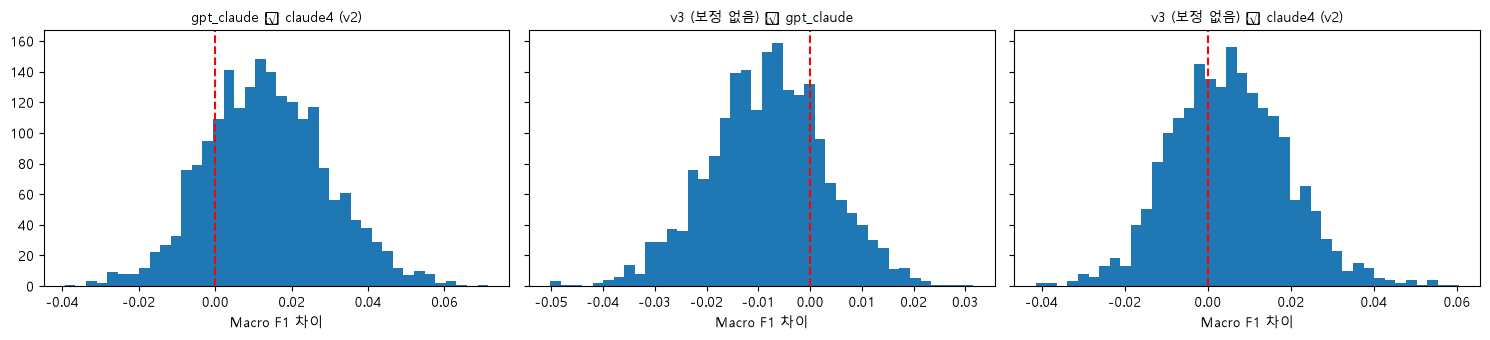

In [14]:
# ============================================================
# 8. [점검 3] 대응 부트스트랩: claude4(v2) vs gpt_claude vs v3
# ============================================================
# 세 모델 모두 같은 개발 데이터로 다시 학습하고 같은 테스트셋에서 비교한다.
# 같은 부트스트랩 표본에서 두 모델의 점수 차이를 계산하므로,
# 테스트셋 구성 운이 두 모델에 똑같이 작용해 차이의 신뢰구간이 좁아진다.
# 부트스트랩은 결함 유형별로 층화해 소수 유형이 빠지는 표본을 막는다.
# ============================================================

X_all_v2 = build_features_v2(df)
v2_model = ScaledSoftVoting(
    [LGBMClassifier(**V2_LGBM), XGBClassifier(**V2_XGB)]
).fit(X_all_v2.iloc[idx_dev], y_dev)
gc_model = ScaledSoftVoting(make_members(), class_scale=GPT_CLAUDE_SCALE).fit(X_dev, y_dev)

preds = {
    "claude4 (v2)": v2_model.predict(X_all_v2.iloc[idx_test]),
    "gpt_claude": gc_model.predict(X_test),
    f"v3 ({FINAL_METHOD})": y_pred,
}
REPORTED = {"claude4 (v2)": 0.8165, "gpt_claude": 0.8349}

print("[재현 확인 - 테스트 Macro F1]")
for name, p in preds.items():
    rep = REPORTED.get(name)
    note = f" (노트북 보고값 {rep:.4f})" if rep else ""
    print(f"  {name:<22} {macro_f1(y_test, p):.4f}{note}")
print("  ※ 학습 데이터 순서·스레드 차이로 보고값과 소수점 셋째 자리 정도 다를 수 있음")


def paired_bootstrap(y, pred_a, pred_b, n_boot=N_BOOT, seed=RANDOM_STATE):
    rng = np.random.default_rng(seed)
    idx_by_class = [np.where(y == k)[0] for k in LABELS if (y == k).any()]
    diffs = np.empty(n_boot)
    for i in range(n_boot):
        b = np.concatenate([rng.choice(ix, len(ix), replace=True) for ix in idx_by_class])
        diffs[i] = macro_f1(y[b], pred_b[b]) - macro_f1(y[b], pred_a[b])
    return diffs


names = list(preds)
pairs = [(names[0], names[1]), (names[1], names[2]), (names[0], names[2])]
boot_rows, boot_diffs = [], {}
for a, b in pairs:
    d = paired_bootstrap(y_test, preds[a], preds[b])
    boot_diffs[f"{b} − {a}"] = d
    lo, hi = np.percentile(d, [2.5, 97.5])

    # McNemar 정확 검정: 한 모델만 맞힌 행의 수를 비교 (정확도 기준)
    ca, cb = preds[a] == y_test, preds[b] == y_test
    n_b_only, n_a_only = int((~ca & cb).sum()), int((ca & ~cb).sum())
    p_mc = (binomtest(min(n_a_only, n_b_only), n_a_only + n_b_only, 0.5).pvalue
            if n_a_only + n_b_only > 0 else 1.0)

    boot_rows.append({
        "비교": f"{b} − {a}",
        "Macro F1 차이": macro_f1(y_test, preds[b]) - macro_f1(y_test, preds[a]),
        "95% CI 하한": lo, "95% CI 상한": hi,
        "P(차이≤0)": (d <= 0).mean(),
        "B만 맞힘": n_b_only, "A만 맞힘": n_a_only,
        "McNemar p": p_mc,
        "판정": "유의한 차이" if (lo > 0 or hi < 0) else "단정 불가",
    })

boot_df = pd.DataFrame(boot_rows)
print("\n[대응 부트스트랩 결과 (테스트, 층화 재표집 %d회)]" % N_BOOT)
display(boot_df.round(4))

fig, axes = plt.subplots(1, len(boot_diffs), figsize=(15, 3.5), sharey=True)
for ax, (label, d) in zip(np.atleast_1d(axes), boot_diffs.items()):
    ax.hist(d, bins=40)
    ax.axvline(0, c="red", ls="--")
    ax.set_title(label, fontsize=10)
    ax.set_xlabel("Macro F1 차이")
plt.tight_layout()
plt.show()

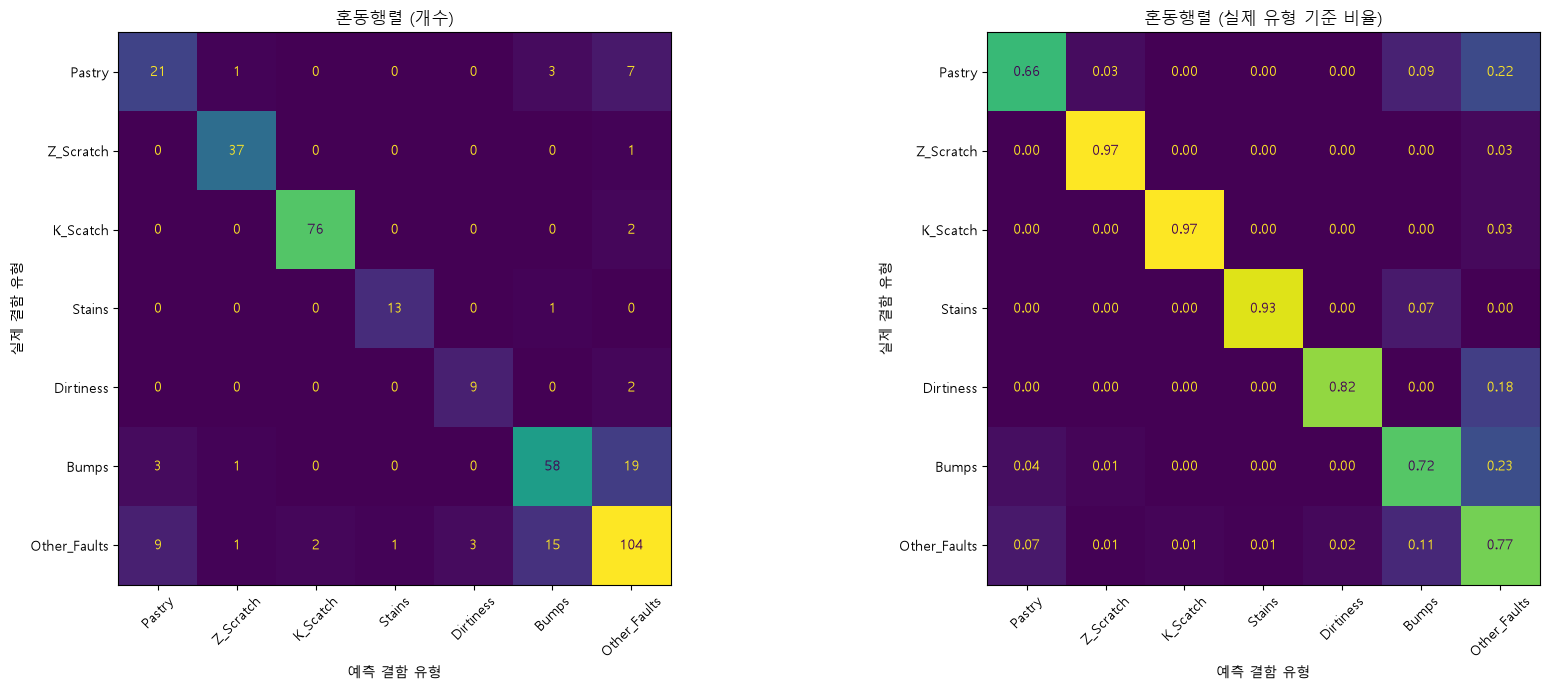


오분류: 71 / 389 (18.25%)


Count
Actual       Predicted          
Bumps        Other_Faults     19
Other_Faults Bumps            15
             Pastry            9
Pastry       Other_Faults      7
Other_Faults Dirtiness         3
Pastry       Bumps             3
Bumps        Pastry            3
K_Scatch     Other_Faults      2
Dirtiness    Other_Faults      2
Other_Faults K_Scatch          2


[Permutation Importance 상위 15개 (테스트)]


,Feature,Importance Mean,Importance SD,강판 단위 변수
0,Length_of_Conveyer,0.0934,0.0167,True
1,Steel_Type,0.0773,0.0113,True
2,Steel_Plate_Thickness,0.0427,0.0136,True
3,Orientation_Index,0.0326,0.0119,False
4,Y_Minimum,0.0278,0.0094,True
5,X_Minimum,0.0253,0.0122,False
6,Minimum_of_Luminosity,0.0157,0.0121,False
7,Edges_Y_Index,0.0142,0.0102,False
8,Square_Index,0.0097,0.0125,False
9,Y_Maximum,0.0077,0.0052,True


In [15]:
# ============================================================
# 9. 테스트 혼동행렬 및 변수 중요도
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(18, 7))
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred, labels=LABELS),
                       display_labels=FAULT_COLS).plot(
    ax=axes[0], xticks_rotation=45, colorbar=False)
axes[0].set_title("혼동행렬 (개수)")
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred, labels=LABELS, normalize="true"),
                       display_labels=FAULT_COLS).plot(
    ax=axes[1], xticks_rotation=45, colorbar=False, values_format=".2f")
axes[1].set_title("혼동행렬 (실제 유형 기준 비율)")
for ax in axes:
    ax.set_xlabel("예측 결함 유형")
    ax.set_ylabel("실제 결함 유형")
plt.tight_layout()
plt.show()

test_result = pd.DataFrame({
    "Actual": [int_to_class[i] for i in y_test],
    "Predicted": [int_to_class[i] for i in y_pred],
}, index=X_test.index)
mis = test_result[test_result["Actual"] != test_result["Predicted"]]
print(f"\n오분류: {len(mis)} / {len(y_test)} ({len(mis) / len(y_test):.2%})")
display(mis.groupby(["Actual", "Predicted"]).size()
        .sort_values(ascending=False).head(10).to_frame("Count"))

perm = permutation_importance(final_model, X_test, y_test, scoring="f1_macro",
                              n_repeats=20, random_state=RANDOM_STATE, n_jobs=-1)
importance_df = (pd.DataFrame({
    "Feature": feature_cols,
    "Importance Mean": perm.importances_mean,
    "Importance SD": perm.importances_std,
    "강판 단위 변수": [c in GROUP_COLS + ["Y_Minimum", "Y_Maximum"] for c in feature_cols],
}).sort_values("Importance Mean", ascending=False).reset_index(drop=True))
print("\n[Permutation Importance 상위 15개 (테스트)]")
display(importance_df.head(15).round(4))

[Bumps vs Other_Faults - 변수별 단독 구분력 상위 12개]


,Feature,AUC,구분력 |AUC-0.5|×2,방향
0,Square_Index,0.678,0.355,Bumps가 큼
1,Steel_Type,0.351,0.299,Other_Faults가 큼
2,Edges_Y_Index,0.641,0.282,Bumps가 큼
3,Y_Minimum,0.639,0.279,Bumps가 큼
4,Y_Maximum,0.639,0.279,Bumps가 큼
5,Empty_Index,0.376,0.247,Other_Faults가 큼
6,Y_Perimeter,0.382,0.236,Other_Faults가 큼
7,X_Perimeter,0.385,0.230,Other_Faults가 큼
8,Edges_Index,0.599,0.197,Bumps가 큼
9,SigmoidOfAreas,0.411,0.178,Other_Faults가 큼


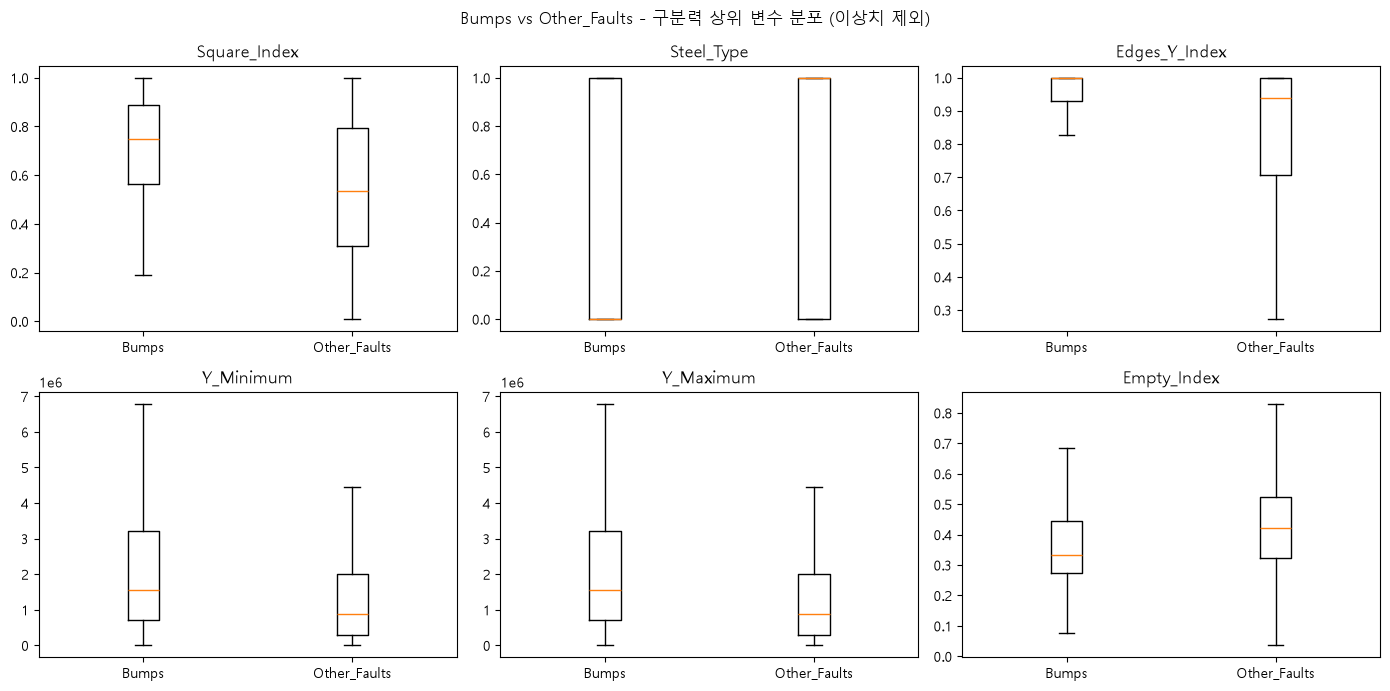


모델 기준 Bumps vs Other_Faults AUC = 0.882
애매 구간(두 유형 확률 비가 0.3~0.7)에 있는 행: 27.3%


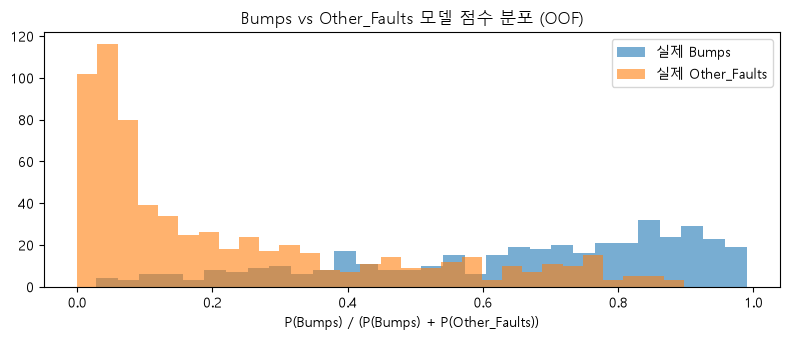


[Bumps/Other_Faults 혼동이 많은 강판 그룹 상위 10개]


,행수,Bumps비율,혼동수,혼동률,혼합 그룹
group,,,,,
1362|40|A400,30,0.433,9,0.300,True
1692|70|A300,26,0.308,8,0.308,True
1358|40|A400,21,0.429,7,0.333,True
1356|40|A400,25,0.360,7,0.280,True
1360|40|A400,37,0.243,7,0.189,True
1650|69|A300,10,0.600,6,0.600,True
1694|80|A300,15,0.800,6,0.400,True
1354|40|A400,13,0.308,6,0.462,True
1356|200|A300,8,0.375,5,0.625,True


[두 유형이 섞인 그룹(Bumps 비율 20~80%) vs 한쪽이 대부분인 그룹]


,행수,혼동수,혼동률
혼합 그룹,,,
False,630,80,0.127
True,445,128,0.288


In [17]:
# ============================================================
# 10. [점검 4-1] Bumps ↔ Other_Faults 구분 분석
# ============================================================
# 전체 데이터에 대해 무작위 5-Fold OOF 확률을 만든다(행마다 그 행을 안 본 모델).
# 이 결과는 분석용이며 모델 선택에는 쓰지 않는다.
# ============================================================

P_all = oof_proba(make_members(), X_all, y_all,
                  StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE))
pred_all = P_all.argmax(axis=1)

B, O = class_to_int["Bumps"], class_to_int["Other_Faults"]
mask_bo = np.isin(y_all, [B, O])
is_bumps = (y_all[mask_bo] == B).astype(int)

# (1) 변수별 단독 구분력: AUC (0.5 = 구분 못함, 1 또는 0 = 완벽)
auc_rows = []
for col in feature_cols:
    vals = X_all.loc[mask_bo, col].to_numpy()
    if np.unique(vals).size < 2:
        continue
    auc = roc_auc_score(is_bumps, vals)
    auc_rows.append({"Feature": col, "AUC": auc, "구분력 |AUC-0.5|×2": abs(auc - 0.5) * 2,
                     "방향": "Bumps가 큼" if auc > 0.5 else "Other_Faults가 큼"})
auc_df = pd.DataFrame(auc_rows).sort_values("구분력 |AUC-0.5|×2", ascending=False).reset_index(drop=True)
print("[Bumps vs Other_Faults - 변수별 단독 구분력 상위 12개]")
display(auc_df.head(12).round(3))

top_feats = auc_df["Feature"].head(6).tolist()
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, col in zip(axes.ravel(), top_feats):
    data = [X_all.loc[mask_bo & (y_all == k), col] for k in (B, O)]
    ax.boxplot(data, showfliers=False)
    ax.set_xticks([1, 2], ["Bumps", "Other_Faults"])
    ax.set_title(col)
plt.suptitle("Bumps vs Other_Faults - 구분력 상위 변수 분포 (이상치 제외)")
plt.tight_layout()
plt.show()

# (2) 모델 기준 구분력: 두 유형 확률만 놓고 본 이진 점수
score_b = P_all[mask_bo, B] / (P_all[mask_bo, B] + P_all[mask_bo, O] + 1e-12)
model_auc = roc_auc_score(is_bumps, score_b)
ambiguous = ((score_b > 0.3) & (score_b < 0.7)).mean()
print(f"\n모델 기준 Bumps vs Other_Faults AUC = {model_auc:.3f}")
print(f"애매 구간(두 유형 확률 비가 0.3~0.7)에 있는 행: {ambiguous:.1%}")

plt.figure(figsize=(8, 3.5))
plt.hist(score_b[is_bumps == 1], bins=30, alpha=0.6, label="실제 Bumps")
plt.hist(score_b[is_bumps == 0], bins=30, alpha=0.6, label="실제 Other_Faults")
plt.xlabel("P(Bumps) / (P(Bumps) + P(Other_Faults))")
plt.title("Bumps vs Other_Faults 모델 점수 분포 (OOF)")
plt.legend()
plt.tight_layout()
plt.show()

# (3) 오분류가 특정 강판 그룹에 몰리는가
bo = pd.DataFrame({"group": group_key[mask_bo].values,
                   "actual": y_all[mask_bo], "pred": pred_all[mask_bo]})
bo["BO 혼동"] = ((bo["actual"] == B) & (bo["pred"] == O)) | ((bo["actual"] == O) & (bo["pred"] == B))
group_bo = bo.groupby("group").agg(
    행수=("actual", "size"),
    Bumps비율=("actual", lambda s: (s == B).mean()),
    혼동수=("BO 혼동", "sum"),
)
group_bo["혼동률"] = group_bo["혼동수"] / group_bo["행수"]
group_bo["혼합 그룹"] = group_bo["Bumps비율"].between(0.2, 0.8)
print("\n[Bumps/Other_Faults 혼동이 많은 강판 그룹 상위 10개]")
display(group_bo.sort_values("혼동수", ascending=False).head(10).round(3))

mix = group_bo.groupby("혼합 그룹")[["행수", "혼동수"]].sum()
mix["혼동률"] = mix["혼동수"] / mix["행수"]
print("[두 유형이 섞인 그룹(Bumps 비율 20~80%) vs 한쪽이 대부분인 그룹]")
display(mix.round(3))

In [18]:
# ============================================================
# 11. [점검 4-2] 라벨 오류 후보 추출
# ============================================================
# 기준 1 (모델): 원래 라벨의 OOF 확률이 낮고, 다른 한 유형의 확률이 높음
# 기준 2 (이웃): 변수 공간에서 가까운 이웃 K개의 라벨 구성
#   → 이웃 대부분이 모델 예측 유형이면 '강한 후보'
# 후보는 사람이 원본 이미지/기록으로 확인해야 하며, 모델 판단으로 라벨을 바꾸지 않는다.
# 라벨을 수정했다면 이 노트북 전체를 처음부터 다시 실행해야 한다
# (특히 테스트 행을 고친 뒤 테스트 점수만 다시 보는 것은 누수).
# ============================================================

p_label = P_all[np.arange(len(y_all)), y_all]
p_pred = P_all.max(axis=1)
suspect = (p_label < SUSPECT_P_LABEL) & (p_pred >= SUSPECT_P_OTHER) & (pred_all != y_all)

Z = QuantileTransformer(output_distribution="normal", n_quantiles=500,
                        random_state=RANDOM_STATE).fit_transform(X_all)
_, nn_idx = NearestNeighbors(n_neighbors=KNN_K + 1).fit(Z).kneighbors(Z)
nn_labels = y_all[nn_idx[:, 1:]]                      # 자기 자신 제외
knn_same_label = (nn_labels == y_all[:, None]).mean(axis=1)
knn_same_pred = (nn_labels == pred_all[:, None]).mean(axis=1)

review = df.copy()
review.insert(0, "row", np.arange(len(df)))
review.insert(1, "set", np.where(np.isin(np.arange(len(df)), idx_test), "test", "dev"))
review.insert(2, "plate_group", group_key.values)
review["predicted"] = [int_to_class[i] for i in pred_all]
review["p_label"] = p_label
review["p_predicted"] = p_pred
review[f"knn{KNN_K}_same_label"] = knn_same_label
review[f"knn{KNN_K}_same_pred"] = knn_same_pred
review["strong"] = (knn_same_pred >= 0.5) & (knn_same_label <= 0.2)

candidates = (review[suspect]
              .sort_values(["strong", "p_predicted"], ascending=[False, False]))

print(f"라벨 오류 후보: {len(candidates)}개 (전체의 {len(candidates) / len(df):.1%}), "
      f"그중 강한 후보 {int(candidates['strong'].sum())}개")
print("\n[후보의 (실제 → 예측) 조합]")
display(candidates.groupby([TARGET, "predicted"]).size()
        .sort_values(ascending=False).to_frame("Count"))

show_cols = ["row", "set", TARGET, "predicted", "p_label", "p_predicted",
             f"knn{KNN_K}_same_label", f"knn{KNN_K}_same_pred", "strong", "plate_group"]
print("\n[라벨 오류 후보 상위 20개]")
display(candidates[show_cols].head(20).round(3))

라벨 오류 후보: 53개 (전체의 2.7%), 그중 강한 후보 28개

[후보의 (실제 → 예측) 조합]


,,Count
Fault_Type,predicted,
Bumps,Other_Faults,16
Other_Faults,Bumps,6
K_Scatch,Other_Faults,5
Other_Faults,K_Scatch,5
Pastry,Other_Faults,4
Dirtiness,Other_Faults,3
Bumps,Pastry,3
Z_Scratch,Other_Faults,2
Other_Faults,Pastry,2



[라벨 오류 후보 상위 20개]


,row,set,Fault_Type,predicted,p_label,p_predicted,knn10_same_label,knn10_same_pred,strong,plate_group
1277,1277,dev,Other_Faults,K_Scatch,0.003,0.997,0.0,1.0,True,1356|40|A400
1276,1276,dev,Other_Faults,K_Scatch,0.003,0.997,0.0,1.0,True,1356|40|A400
816,816,test,Dirtiness,Other_Faults,0.006,0.904,0.1,0.6,True,1353|120|A400
812,812,dev,Dirtiness,Other_Faults,0.014,0.901,0.1,0.7,True,1353|120|A400
1612,1612,dev,Other_Faults,Bumps,0.102,0.895,0.2,0.8,True,1692|70|A300
1464,1464,dev,Other_Faults,Bumps,0.121,0.877,0.0,1.0,True,1694|80|A300
1592,1592,dev,Other_Faults,K_Scatch,0.066,0.874,0.0,1.0,True,1387|40|A400
1254,1254,test,Bumps,Pastry,0.039,0.870,0.1,0.7,True,1358|70|A300
870,870,dev,Bumps,Other_Faults,0.122,0.850,0.2,0.8,True,1353|185|A400
1099,1099,dev,Bumps,Other_Faults,0.089,0.842,0.0,0.9,True,1364|40|A400


In [ ]:
# ============================================================
# 12. 전체 데이터로 재학습 및 저장, 예측 함수
# ============================================================

deploy_model = ScaledSoftVoting(make_members(), class_scale=final_scale).fit(X_all, y_all)
joblib.dump({
    "model": deploy_model,
    "members": ["LightGBM", "Extra Trees"],
    "params": {"LightGBM": LGBM_TUNED, "Extra Trees": ET_TUNED},
    "class_scale": None if final_scale is None else list(final_scale),
    "scale_method": FINAL_METHOD,
    "precision_floor": PRECISION_FLOOR,
    "feature_cols": feature_cols,
    "class_names": FAULT_COLS,
    "test_scores": test_scores,
    "group_cv_macro_f1": cv_compare.loc["그룹 CV", "mean"],
}, "steel_fault_model_v3.joblib")


def predict_faults(new_data: pd.DataFrame,
                   model_path: str = "steel_fault_model_v3.joblib") -> pd.DataFrame:
    """원본 형식(TypeOfSteel_A300/A400) 또는 병합 형식(Steel_Type) 모두 입력 가능.
    ScaledSoftVoting 클래스가 정의된 환경에서 불러와야 한다."""
    bundle = joblib.load(model_path)
    names = bundle["class_names"]
    merged = merge_columns(new_data.drop(columns=names, errors="ignore"))
    X_new = build_features(merged)[bundle["feature_cols"]]
    proba = bundle["model"].predict_proba(X_new)
    out = pd.DataFrame(proba, columns=[f"prob_{n}" for n in names], index=new_data.index)
    out.insert(0, "predicted_fault", [names[i] for i in proba.argmax(axis=1)])
    out.insert(1, "confidence", proba.max(axis=1))
    return out


demo = predict_faults(raw_df.iloc[idx_test[:5]])
demo.insert(0, "actual_fault", df.iloc[idx_test[:5]][TARGET].values)
print("[예측 함수 동작 확인 - 전체 데이터로 재학습한 모델이므로 성능 지표 아님]")
display(demo.round(3))

[예측 함수 동작 확인 - 전체 데이터로 재학습한 모델이므로 성능 지표 아님]


,actual_fault,predicted_fault,confidence,prob_Pastry,prob_Z_Scratch,prob_K_Scatch,prob_Stains,prob_Dirtiness,prob_Bumps,prob_Other_Faults
904,Bumps,Bumps,0.983,0.003,0.000,0.000,0.0,0.0,0.983,0.013
492,K_Scatch,K_Scatch,1.000,0.000,0.000,1.000,0.0,0.0,0.000,0.000
232,Z_Scratch,Z_Scratch,0.991,0.000,0.991,0.000,0.0,0.0,0.002,0.008
1093,Bumps,Bumps,0.870,0.008,0.000,0.004,0.0,0.0,0.870,0.118
803,Stains,Stains,1.000,0.000,0.000,0.000,1.0,0.0,0.000,0.000


In [20]:
# ============================================================
# 13. 최종 요약
# ============================================================

print("=" * 60)
print("최종 요약 (v3)")
print("=" * 60)
print(f"유사 강판 그룹: {len(group_sizes)}개 ({' + '.join(GROUP_COLS)})")
print(f"그룹 다수결 기준선 (무작위 CV) Macro F1: {macro_f1(y_all, gm_random):.4f}")
print("\n[점검 1] 무작위 CV vs 그룹 CV (개발 데이터, 보정 없음)")
print(f"  무작위 CV {cv_compare.loc['무작위 CV', 'mean']:.4f} / "
      f"그룹 CV {cv_compare.loc['그룹 CV', 'mean']:.4f} → 차이 {group_gap:+.4f}")
print("\n[점검 2] 확률 보정 (그룹 CV 바깥 fold 기준)")
for m in METHODS[1:]:
    print(f"  {m}: 이득 {summary.loc[('그룹 CV', m), '이득(평균)']:+.4f}, "
          f"Pastry 정밀도 {summary.loc[('그룹 CV', m), 'Pastry Precision']:.3f}")
print(f"  → 최종 방식: {FINAL_METHOD}")
print("\n[점검 3] 테스트 대응 부트스트랩")
for _, r in boot_df.iterrows():
    print(f"  {r['비교']}: {r['Macro F1 차이']:+.4f} "
          f"[{r['95% CI 하한']:+.4f}, {r['95% CI 상한']:+.4f}] → {r['판정']}")
print("\n[점검 4] Bumps vs Other_Faults")
print(f"  모델 AUC {model_auc:.3f}, 애매 구간 {ambiguous:.1%}, "
      f"단독 구분력 1위 변수 {auc_df.iloc[0]['Feature']}")
print(f"  라벨 오류 후보 {len(candidates)}개 (강한 후보 {int(candidates['strong'].sum())}개)"
      " → v3_label_review_candidates.csv")
print(f"\n최종 테스트: Macro F1 {test_scores['Macro F1']:.4f}, Accuracy {test_scores['Accuracy']:.4f}")
print("※ 새 강판에 대한 기대 성능은 테스트 점수보다 그룹 CV 점수에 가깝다고 보는 편이 안전하다.")

최종 요약 (v3)
유사 강판 그룹: 239개 (Length_of_Conveyer + Steel_Plate_Thickness + Steel_Type)
그룹 다수결 기준선 (무작위 CV) Macro F1: 0.6948

[점검 1] 무작위 CV vs 그룹 CV (개발 데이터, 보정 없음)
  무작위 CV 0.8265 / 그룹 CV 0.7041 → 차이 +0.1224

[점검 2] 확률 보정 (그룹 CV 바깥 fold 기준)
  자유 보정: 이득 -0.0012, Pastry 정밀도 0.582
  제약 보정: 이득 -0.0195, Pastry 정밀도 0.692
  → 최종 방식: 보정 없음

[점검 3] 테스트 대응 부트스트랩
  gpt_claude − claude4 (v2): +0.0136 [-0.0163, +0.0459] → 단정 불가
  v3 (보정 없음) − gpt_claude: -0.0085 [-0.0311, +0.0140] → 단정 불가
  v3 (보정 없음) − claude4 (v2): +0.0051 [-0.0213, +0.0349] → 단정 불가

[점검 4] Bumps vs Other_Faults
  모델 AUC 0.882, 애매 구간 27.3%, 단독 구분력 1위 변수 Square_Index
  라벨 오류 후보 53개 (강한 후보 28개) → v3_label_review_candidates.csv

최종 테스트: Macro F1 0.8264, Accuracy 0.8175
※ 새 강판에 대한 기대 성능은 테스트 점수보다 그룹 CV 점수에 가깝다고 보는 편이 안전하다.
